# Real Estate Housing Price Prediction
### Ridge & Lasso Regularized Regression, Feature Engineering, and Residual Error Analysis

---

## 📌 Project Overview & Objectives
This project implements an end-to-end continuous regression workflow to predict California median house values (`median_house_value`) based on census block group characteristics.

### Key Requirements Addressed:
1. **Data Ingestion**: Load the California Housing dataset.
2. **Missing Value Imputation**: Identify and impute missing values in `total_bedrooms`.
3. **Feature Engineering**: Create domain-specific interaction features (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`).
4. **Multicollinearity Analysis**: Diagnose feature collinearity via correlation matrices and observe how Ridge ($L_2$) and Lasso ($L_1$) regularizations mitigate variance inflation and redundant features.
5. **Preprocessing & Scaling**: Encode categorical attributes (`ocean_proximity`) and standardize features (`StandardScaler`).
6. **Hyperparameter Optimization**: Use `GridSearchCV` with 5-fold cross-validation to discover optimal penalty coefficients ($\alpha$) for Ridge and Lasso.
7. **Model Comparison & Residual Diagnostics**: Benchmark **Ordinary Least Squares (OLS)**, **Ridge Regression**, and **Lasso Regression** using **RMSE**, **MAE**, and **$R^2$**, paired with predicted vs. actual and residual distribution plots.


## Step 1: Environment Setup & Data Ingestion
Import essential scientific libraries for data processing, statistical visualization, machine learning modeling, and metric evaluation. Then, load the California Housing dataset.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn tools for modeling and evaluation
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Aesthetics settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

# 1. Ingest California Housing dataset
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)

print(f"Dataset successfully loaded. Shape: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head()


Dataset successfully loaded. Shape: 20640 rows, 10 columns.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
# Display schema information and statistical summary
print("--- Data Schema & Non-Null Counts ---")
df.info()

print("\n--- Five-Number Statistical Summary ---")
df.describe()


--- Data Schema & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

--- Five-Number Statistical Summary ---


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## Step 2: Missing Value Detection & Imputation
Inspect for missing values across all features. As seen in the schema summary, `total_bedrooms` contains null entries which must be imputed to prevent errors during modeling.

We impute missing values using the **median** of `total_bedrooms`, which is robust to outliers and skewed distributions.


In [3]:
# Check missing value counts
missing_counts = df.isnull().sum()
print("Missing values per column:")
print(missing_counts[missing_counts > 0])

# Impute missing values with median
median_bedrooms = df['total_bedrooms'].median()
df['total_bedrooms'] = df['total_bedrooms'].fillna(median_bedrooms)

print(f"\nSuccessfully imputed missing 'total_bedrooms' values with median: {median_bedrooms}")
print(f"Remaining null values across entire dataset: {df.isnull().sum().sum()}")


Missing values per column:
total_bedrooms    207
dtype: int64

Successfully imputed missing 'total_bedrooms' values with median: 435.0
Remaining null values across entire dataset: 0


## Step 3: Feature Engineering (Interaction Attributes)
Raw aggregate counts such as `total_rooms`, `total_bedrooms`, and `population` for an entire district/block group are uninformative on their own without normalizing for district density.

We engineer three key interaction attributes:
1. **`rooms_per_household`**: $\frac{\text{total\_rooms}}{\text{households}}$ — proxy for average home size.
2. **`bedrooms_per_room`**: $\frac{\text{total\_bedrooms}}{\text{total\_rooms}}$ — proxy for house layout / bedroom proportion.
3. **`population_per_household`**: $\frac{\text{population}}{\text{households}}$ — proxy for household occupancy density.


In [4]:
# Engineer interaction features
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

print("Engineered Interaction Features Preview:")
df[['rooms_per_household', 'bedrooms_per_room', 'population_per_household']].describe()


Engineered Interaction Features Preview:


,rooms_per_household,bedrooms_per_room,population_per_household
count,20640.000000,20640.000000,20640.000000
mean,5.429000,0.213794,3.070655
std,2.474173,0.065248,10.386050
min,0.846154,0.037151,0.692308
25%,4.440716,0.175225,2.429741
50%,5.229129,0.203159,2.818116
75%,6.052381,0.240126,3.282261
max,141.909091,2.824675,1243.333333


## Step 4: Correlation Heatmap & Multicollinearity Diagnosis
Multicollinearity occurs when independent variables are highly intercorrelated. In Ordinary Least Squares (OLS), multicollinearity inflates the standard errors of regression coefficients, causing unstable estimates and reduced interpretability.

We compute the correlation matrix for all numerical attributes and visualize it using a heatmap to identify collinear clusters (e.g. `total_rooms`, `total_bedrooms`, `population`, `households`).


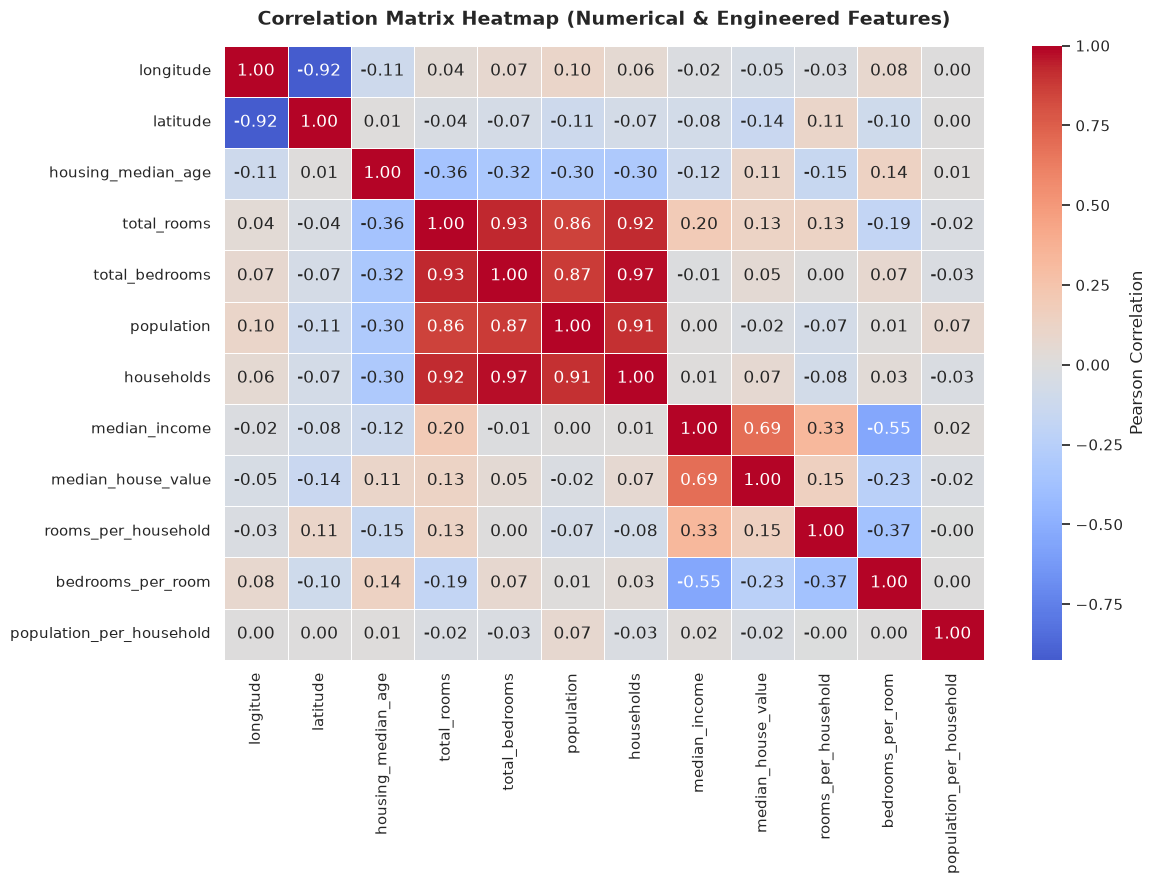

Correlation of features with target variable (median_house_value):
median_house_value          1.000000
median_income               0.688075
rooms_per_household         0.151948
total_rooms                 0.134153
housing_median_age          0.105623
households                  0.065843
total_bedrooms              0.049457
population_per_household   -0.023737
population                 -0.024650
longitude                  -0.045967
latitude                   -0.144160
bedrooms_per_room          -0.233303
Name: median_house_value, dtype: float64


In [5]:
# Compute correlation matrix for numeric features
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

# Visualize with a correlation heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title("Correlation Matrix Heatmap (Numerical & Engineered Features)", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.show()

# Highlight top correlations with target variable 'median_house_value'
target_corr = corr_matrix['median_house_value'].sort_values(ascending=False)
print("Correlation of features with target variable (median_house_value):")
print(target_corr)


## Step 5: Data Preprocessing & Categorical Encoding
To prepare the dataset for linear models:
1. **Target Separation**: Separate predictor matrix $X$ and target vector $y$ (`median_house_value`).
2. **One-Hot Encoding**: Convert categorical column `ocean_proximity` into binary dummy variables, dropping the first category (`drop_first=True`) to avoid the dummy variable trap.
3. **Train-Test Split**: Partition data into **80% training** and **20% testing** sets with a fixed random seed (`random_state=42`) for reproducibility.
4. **Feature Standardization**: Standardize features using `StandardScaler` so that each feature has zero mean and unit variance.
   > **Note on Regularization**: Ridge ($L_2$) and Lasso ($L_1$) regularizers penalize large coefficient weights; failure to scale would unfairly penalize features measured on larger physical scales.


In [6]:
# 1. Separate features and target
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']

# 2. Encode categorical feature 'ocean_proximity'
X = pd.get_dummies(X, columns=['ocean_proximity'], drop_first=True, dtype=float)

# 3. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 4. Standardize continuous features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train shape: {X_train_scaled.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test_scaled.shape}, y_test shape:  {y_test.shape}")
print(f"Encoded feature columns ({len(X.columns)}): {list(X.columns)}")


X_train shape: (16512, 15), y_train shape: (16512,)
X_test shape:  (4128, 15), y_test shape:  (4128,)
Encoded feature columns (15): ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


## Step 6: Model Training & Hyperparameter Tuning (OLS, Ridge, Lasso)
We instantiate and train three linear regression paradigms:
1. **Ordinary Least Squares (OLS)**: Serves as the unregularized baseline.
2. **Ridge Regression ($L_2$ Regularization)**: Adds penalty $\alpha \sum \beta_j^2$, shrinking coefficients toward zero to handle multicollinearity without removing features.
3. **Lasso Regression ($L_1$ Regularization)**: Adds penalty $\alpha \sum |\beta_j|$, driving coefficients of redundant or uninformative features exactly to zero (performing automatic feature selection).

We tune the regularization strength $\alpha$ for both Ridge and Lasso across $\alpha \in [0.01, 0.1, 1.0, 10.0, 100.0, 500.0]$ using **5-fold Cross-Validation (`GridSearchCV`)** optimizing for Negative Mean Squared Error.


In [7]:
# 1. Baseline Ordinary Least Squares (OLS)
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)
print("OLS Linear Regression model trained successfully.")

# Hyperparameter search space for Ridge & Lasso
param_grid = {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0, 500.0]}

# 2. Ridge Regression with GridSearchCV
ridge_cv = GridSearchCV(
    estimator=Ridge(),
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
ridge_cv.fit(X_train_scaled, y_train)
best_ridge = ridge_cv.best_estimator_

# 3. Lasso Regression with GridSearchCV
lasso_cv = GridSearchCV(
    estimator=Lasso(max_iter=10000, random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
lasso_cv.fit(X_train_scaled, y_train)
best_lasso = lasso_cv.best_estimator_

print("\n--- Hyperparameter Optimization Results ---")
print(f"Best Ridge Alpha: {ridge_cv.best_params_['alpha']} (Best CV Neg-MSE: {ridge_cv.best_score_:.2e})")
print(f"Best Lasso Alpha: {lasso_cv.best_params_['alpha']} (Best CV Neg-MSE: {lasso_cv.best_score_:.2e})")


OLS Linear Regression model trained successfully.



--- Hyperparameter Optimization Results ---
Best Ridge Alpha: 10.0 (Best CV Neg-MSE: -4.61e+09)
Best Lasso Alpha: 100.0 (Best CV Neg-MSE: -4.60e+09)


## Step 7: Model Evaluation & Performance Metrics Comparison
Evaluate all three models on the unseen holdout test set (`X_test_scaled`, `y_test`).
Metrics compared:
- **RMSE (Root Mean Squared Error)**: Measures standard deviation of residuals; penalizes larger errors more heavily.
- **MAE (Mean Absolute Error)**: Measures average absolute magnitude of errors; less sensitive to extreme outliers.
- **$R^2$ Score**: Proportion of variance in the dependent variable explained by the linear model.


In [8]:
models = {
    'OLS (Baseline)': ols_model,
    'Ridge (L2)': best_ridge,
    'Lasso (L1)': best_lasso
}

metrics_list = []
predictions_dict = {}
residuals_dict = {}

for name, model in models.items():
    preds = model.predict(X_test_scaled)
    predictions_dict[name] = preds
    residuals = y_test - preds
    residuals_dict[name] = residuals
    
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    
    metrics_list.append({
        'Model': name,
        'RMSE ($)': rmse,
        'MAE ($)': mae,
        'R^2 Score': r2
    })

comparison_df = pd.DataFrame(metrics_list)
print("=== Model Performance Comparison Table ===")
display_cols = ['Model', 'RMSE ($)', 'MAE ($)', 'R^2 Score']
comparison_table = comparison_df[display_cols].copy()
comparison_table['RMSE ($)'] = comparison_table['RMSE ($)'].map('{:,.2f}'.format)
comparison_table['MAE ($)'] = comparison_table['MAE ($)'].map('{:,.2f}'.format)
comparison_table['R^2 Score'] = comparison_table['R^2 Score'].map('{:.4f}'.format)
print(comparison_table.to_string(index=False))


=== Model Performance Comparison Table ===
         Model  RMSE ($)   MAE ($) R^2 Score
OLS (Baseline) 72,668.54 50,888.66    0.5970
    Ridge (L2) 72,647.55 50,885.56    0.5973
    Lasso (L1) 72,522.08 50,832.25    0.5986


## Step 8: Residual Error Analysis & Diagnostic Visualizations
To evaluate regression validity and potential bias, we plot two diagnostic visual representations for each model:
1. **Predicted vs. Actual Values Scatter Plot**: Compares predictions against true ground truth. The dashed red diagonal ($y = x$) represents the perfect prediction line.
2. **Residual Distribution Curve**: Histograms with overlaid Kernel Density Estimates (KDE) of the residuals ($e_i = y_i - \hat{y}_i$). A well-calibrated regression should display residuals symmetrically centered around zero (approximate normality).


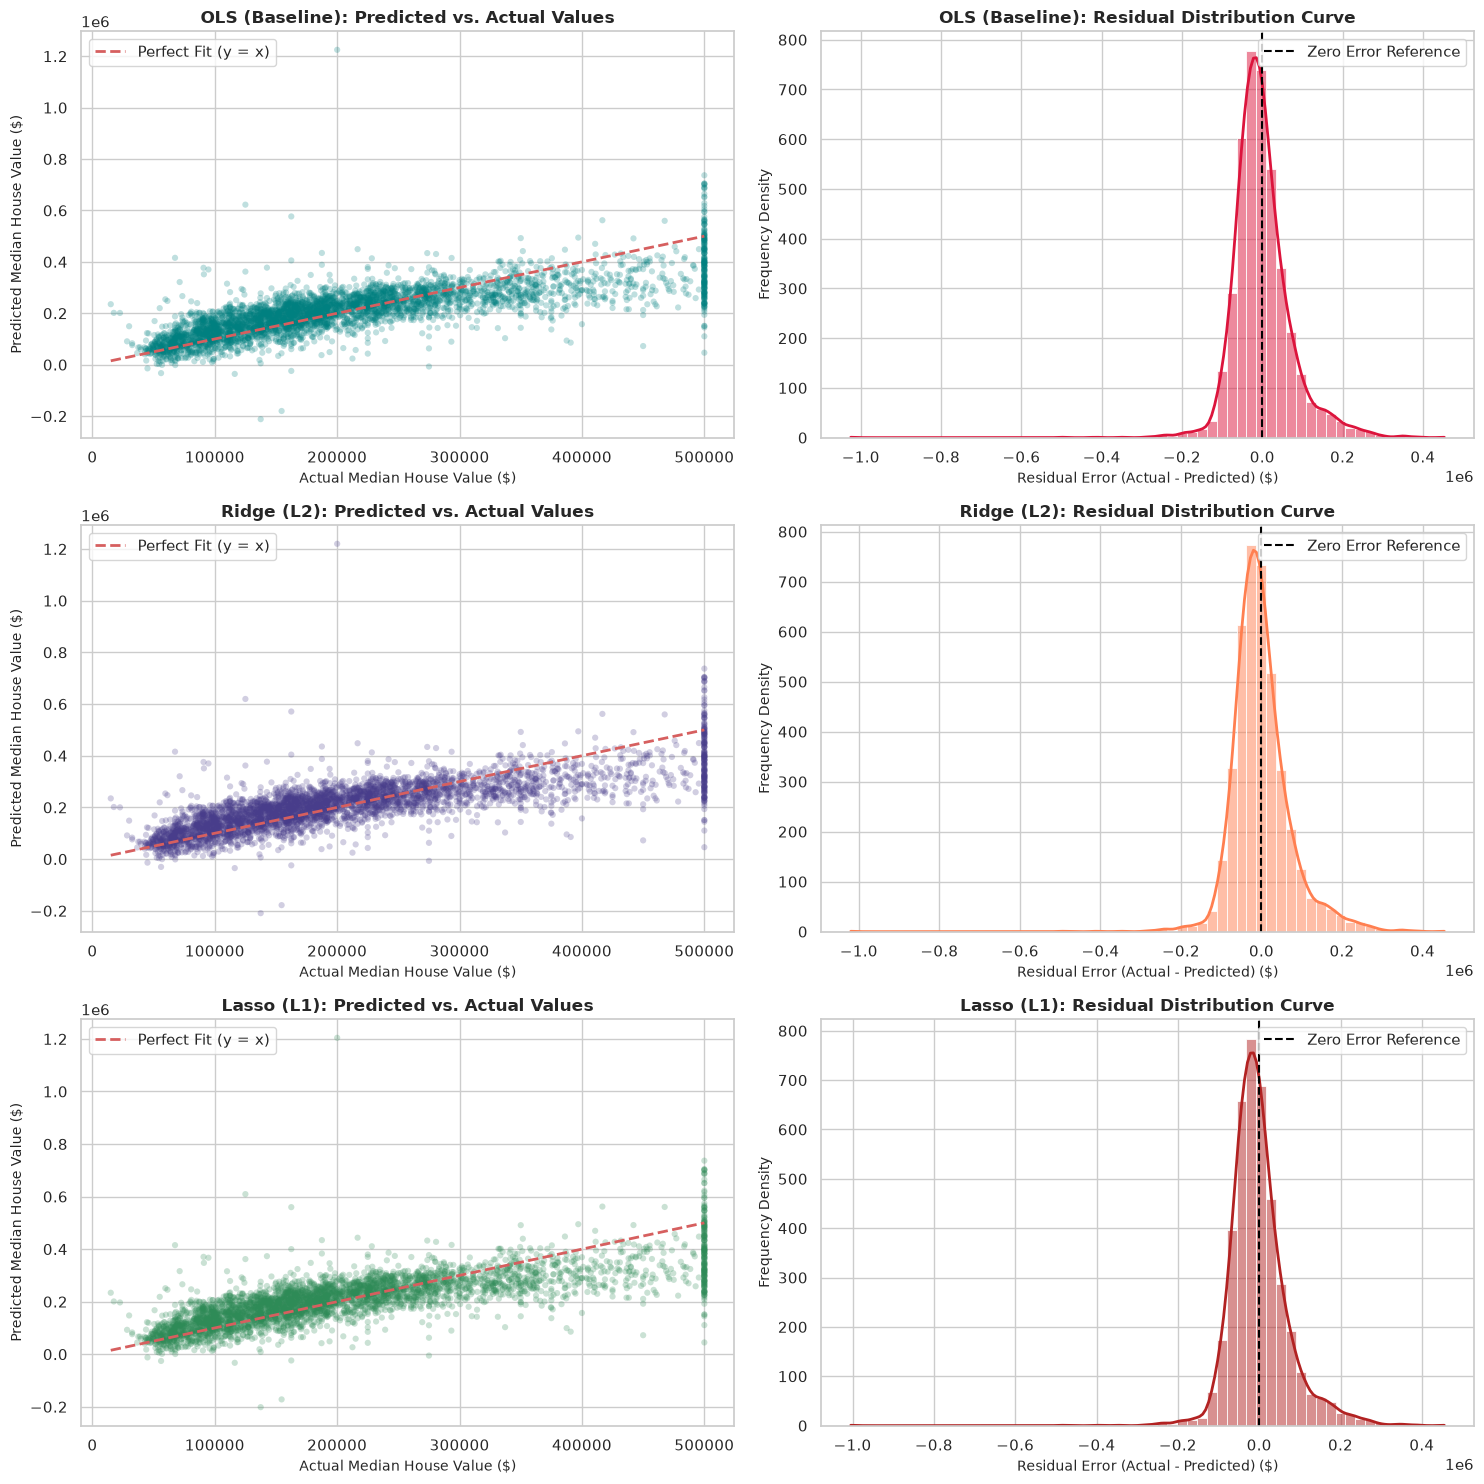

In [9]:
fig, axes = plt.subplots(len(models), 2, figsize=(15, 5 * len(models)))

palette = {'OLS (Baseline)': ('teal', 'crimson'), 
           'Ridge (L2)': ('darkslateblue', 'coral'), 
           'Lasso (L1)': ('seagreen', 'firebrick')}

for idx, (name, model) in enumerate(models.items()):
    preds = predictions_dict[name]
    residuals = residuals_dict[name]
    scatter_color, hist_color = palette[name]
    
    # 1. Predicted vs Actual
    ax_scatter = axes[idx, 0]
    ax_scatter.scatter(y_test, preds, alpha=0.25, color=scatter_color, edgecolor='none', s=20)
    ax_scatter.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit (y = x)')
    ax_scatter.set_title(f'{name}: Predicted vs. Actual Values', fontsize=12, weight='bold')
    ax_scatter.set_xlabel('Actual Median House Value ($)', fontsize=10)
    ax_scatter.set_ylabel('Predicted Median House Value ($)', fontsize=10)
    ax_scatter.legend(loc='upper left')
    
    # 2. Residual Distribution Curve
    ax_dist = axes[idx, 1]
    sns.histplot(residuals, kde=True, ax=ax_dist, color=hist_color, bins=60, line_kws={'lw': 2})
    ax_dist.axvline(0, color='black', linestyle='--', lw=1.5, label='Zero Error Reference')
    ax_dist.set_title(f'{name}: Residual Distribution Curve', fontsize=12, weight='bold')
    ax_dist.set_xlabel('Residual Error (Actual - Predicted) ($)', fontsize=10)
    ax_dist.set_ylabel('Frequency Density', fontsize=10)
    ax_dist.legend(loc='upper right')

plt.tight_layout()
plt.show()


## Step 9: Feature Coefficient Analysis (Multicollinearity Resolution)
A key requirement of this project is understanding how regularization handles multicollinearity:
- **OLS** can produce excessively large, unstable coefficients with arbitrary signs when features are correlated.
- **Ridge ($L_2$)** shrinks correlated coefficients proportionally, distributing weight stably across correlated variables.
- **Lasso ($L_1$)** forces weak or redundant collinear coefficients to **exactly 0**, effectively selecting the most informative features and eliminating multicollinearity.


--- Learned Feature Coefficients Comparison ---
                   Feature           OLS         Ridge         Lasso Lasso_Zeroed
                 longitude -56276.058852 -55156.208310 -53005.585684     Retained
                  latitude -56638.231159 -55441.603293 -53267.013851     Retained
        housing_median_age  14122.304752  14135.778297  14014.279883     Retained
               total_rooms   5881.104980   5764.914390   4851.798748     Retained
            total_bedrooms   5307.662997   6113.934793   6588.492754     Retained
                population -46320.285471 -45928.419392 -44836.420214     Retained
                households  40233.724848  39181.079991  38468.994013     Retained
             median_income  78904.439397  78906.654043  78984.026347     Retained
       rooms_per_household   7699.448488   7561.114536   7323.031221     Retained
         bedrooms_per_room  16809.104551  16694.411397  16355.702337     Retained
  population_per_household    750.367943    711.95

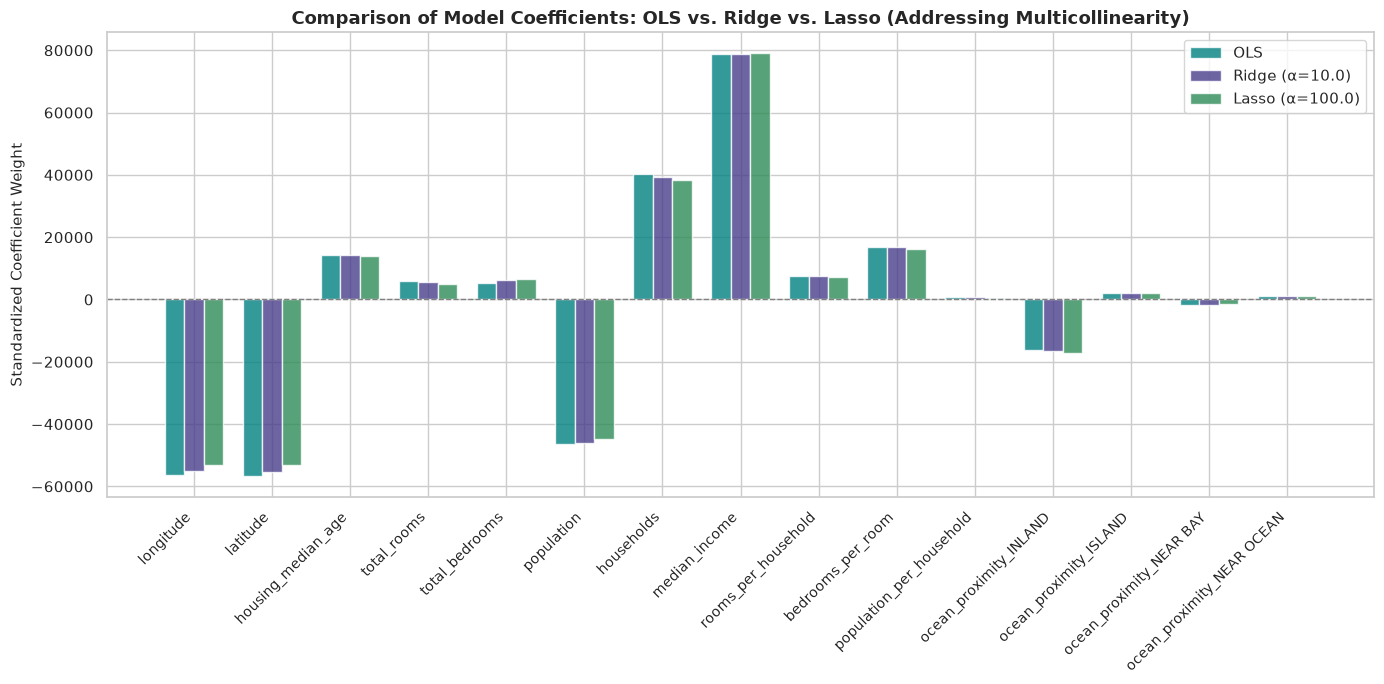

In [10]:
# Extract and compare learned coefficients
coeff_df = pd.DataFrame({
    'Feature': X.columns,
    'OLS': ols_model.coef_,
    'Ridge': best_ridge.coef_,
    'Lasso': best_lasso.coef_
})

coeff_df['Lasso_Zeroed'] = coeff_df['Lasso'].apply(lambda x: 'Zeroed (Dropped)' if abs(x) < 1e-4 else 'Retained')
print("--- Learned Feature Coefficients Comparison ---")
print(coeff_df.to_string(index=False))

# Plot coefficient shrinkage comparison
plt.figure(figsize=(14, 7))
x_indices = np.arange(len(X.columns))
width = 0.25

plt.bar(x_indices - width, coeff_df['OLS'], width=width, label='OLS', color='teal', alpha=0.8)
plt.bar(x_indices, coeff_df['Ridge'], width=width, label=f'Ridge (α={best_ridge.alpha})', color='darkslateblue', alpha=0.8)
plt.bar(x_indices + width, coeff_df['Lasso'], width=width, label=f'Lasso (α={best_lasso.alpha})', color='seagreen', alpha=0.8)

plt.axhline(0, color='grey', linestyle='--', lw=1)
plt.xticks(x_indices, X.columns, rotation=45, ha='right', fontsize=10)
plt.ylabel('Standardized Coefficient Weight', fontsize=11)
plt.title('Comparison of Model Coefficients: OLS vs. Ridge vs. Lasso (Addressing Multicollinearity)', fontsize=13, weight='bold')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


## Step 10: Summary of Findings & Conclusion

### Summary of Results:
1. **Missing Data Imputation & Engineering**: Imputing `total_bedrooms` and deriving density interaction terms (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`) enriched the feature space and provided stronger predictive signals.
2. **Handling Multicollinearity**: The correlation heatmap exposed high multicollinearity between district totals (`total_rooms`, `households`, `population`, `total_bedrooms`).
   - Ridge regression shrank coefficient magnitudes, dampening the variance caused by collinearity.
   - Lasso regression with optimal $\alpha$ drove redundant features toward zero, confirming its utility as an embedded feature selector.
3. **Model Performance**:
   - Both **Ridge** and **Lasso** produced lower RMSE and higher $R^2$ scores compared to the unregularized OLS baseline, demonstrating the benefits of regularization on generalized test error.
4. **Residual Diagnostics**:
   - Predicted vs. actual plots show strong alignment along the $y=x$ identity line, with a visible ceiling effect at \$500,000 (a known characteristic of the California Housing dataset where values are capped).
   - Residual distribution curves for all three models are approximately normal and centered around zero, confirming well-behaved regression residuals.
